# Statistical and Machine Learning
### HW1 : Introduction and Learnability
---
Cyprien  Loric - M2 IMDS - Université de Haute-Alsace

## Imports

In [1]:
import random

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
random.seed(42)

## I - Data Generation

In [2]:
# Constantes
m = [5, 10, 20, 50, 100, 200]
teta = random.uniform(0, 1)
epsilon = 0.1
eta = 0.2
delta = 0.05

In [3]:
datasets = []

for nbr_samples in m:
    samples = []
    for i in range(nbr_samples):
        x = random.uniform(0, 1)
        if x > teta:
            y = 1
        else:
            y = 0
        samples.append((x,y))

    datasets.append(samples)

for i in range(2):
    print(f"dataset_{i} : {len(datasets[i])}")
    print(f"dataset_{i} : {datasets[i]}")
    print("\n")

dataset_0 : 5
dataset_0 : [(0.025010755222666936, 0), (0.27502931836911926, 0), (0.22321073814882275, 0), (0.7364712141640124, 1), (0.6766994874229113, 1)]


dataset_1 : 10
dataset_1 : [(0.8921795677048454, 1), (0.08693883262941615, 0), (0.4219218196852704, 0), (0.029797219438070344, 0), (0.21863797480360336, 0), (0.5053552881033624, 0), (0.026535969683863625, 0), (0.1988376506866485, 0), (0.6498844377795232, 1), (0.5449414806032167, 0)]




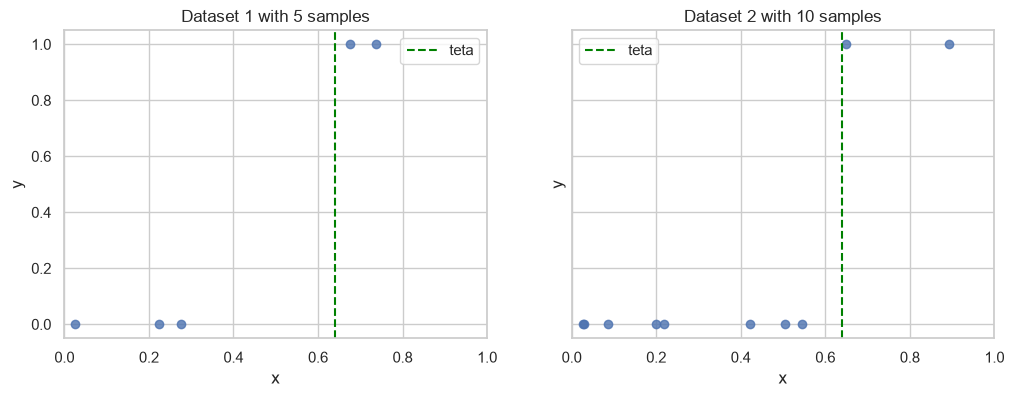

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12,4), sharex=True, sharey=True)

for i in range(len(axes)):
    ax = axes[i]
    x_vals = [datasets[i][j][0] for j in range(len(datasets[i]))]
    y_vals = [datasets[i][j][1] for j in range(len(datasets[i]))]

    ax.scatter(x_vals, y_vals, alpha=0.8)
    ax.axvline(x=teta, color="green", linestyle="--", label="teta")
    ax.set_title(f"Dataset {i+1} with {len(datasets[i])} samples")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_xlim(0, 1)
    ax.legend()

## II - Implementation of ERM

In [5]:
def ERM (dataset):

    sorted_dataset = sorted(dataset)

    candidates = []
    for i in range(len(sorted_dataset) - 1):
        middle = (sorted_dataset[i+1][0] + sorted_dataset[i][0])/2
        candidates.append(middle)

    best_teta = 0
    best_error = float("inf")
    for candidate in candidates:
        cpt_error = 0
        for x, y in dataset:
            if x > candidate:
                prediction = 1
            else:
                prediction = 0

            if y != prediction:
                cpt_error += 1

        error = cpt_error / len(dataset)

        if error < best_error:
            best_error = error
            best_teta = candidate

    return best_teta, best_error

In [6]:
for i in range(len(datasets)):
    best_teta, best_error = ERM(datasets[i])
    print(f"m={m[i]}: best_teta = {best_teta:.4f}, empirical error = {best_error:.4f}")

m=5: best_teta = 0.4759, empirical error = 0.0000
m=10: best_teta = 0.5974, empirical error = 0.0000
m=20: best_teta = 0.6509, empirical error = 0.0000
m=50: best_teta = 0.6378, empirical error = 0.0000
m=100: best_teta = 0.6400, empirical error = 0.0000
m=200: best_teta = 0.6393, empirical error = 0.0000


The empirical error only changes when teta crosses a training point, because this is when the prediction for that point changes. Between two consecutive points, the classifier gives the same result. So we only need to test one theta per interval, and we take the middle of each pair of consecutive points. For each candidate, we count the number of errors and we keep the one with the fewest errors. We test all possible cases.

## III - Performance Evaluation

In [7]:
def True_Error (teta, best_teta, test_size):
    cpt_error = 0
    for i in range (test_size):
        x = random.uniform(0,1)
        if x > teta:
            y = 1
        else:
            y = 0

        if x > best_teta:
            prediction = 1
        else:
            prediction = 0

        if y != prediction:
            cpt_error +=1

    true_error = cpt_error / test_size
    return true_error

In [8]:
for i in range(len(datasets)):
    best_teta, best_error = ERM(datasets[i])
    true_error = True_Error(teta, best_teta, 1000)
    print(f"m={m[i]}: empirical error = {best_error:.4f}, true error = {true_error:.4f}")

m=5: empirical error = 0.0000, true error = 0.1670
m=10: empirical error = 0.0000, true error = 0.0410
m=20: empirical error = 0.0000, true error = 0.0120
m=50: empirical error = 0.0000, true error = 0.0000
m=100: empirical error = 0.0000, true error = 0.0000
m=200: empirical error = 0.0000, true error = 0.0000


The empirical error is always 0. A threshold that separates the training labels perfectly always exists, and ERM always finds it. The true error is not 0 for small m, but it goes down when m grows. This difference between the empirical error and the true error happens because we dont know the exact position of teta even more when we only have a few points.

## IV - Experimental Verifications of PAC Learning

In [9]:
probs_pac = []

for nbr_samples in m:
    count = 0    
    for repe in range(1000):
        samples = []
        for i in range(nbr_samples):
            x = random.uniform(0, 1)
            if x > teta:
                y = 1
            else:
                y = 0
            samples.append((x,y))
   
        best_teta, best_error = ERM(samples)
        true_error = True_Error(teta, best_teta, 1000)

        if true_error > epsilon:
            count += 1

    prob = count / 1000
    probs_pac.append(prob)

    print(f"m={nbr_samples}: Pr(L(h) > {epsilon}) = {prob:.4f}")

m=5: Pr(L(h) > 0.1) = 0.2910
m=10: Pr(L(h) > 0.1) = 0.0980
m=20: Pr(L(h) > 0.1) = 0.0160
m=50: Pr(L(h) > 0.1) = 0.0000
m=100: Pr(L(h) > 0.1) = 0.0000
m=200: Pr(L(h) > 0.1) = 0.0000


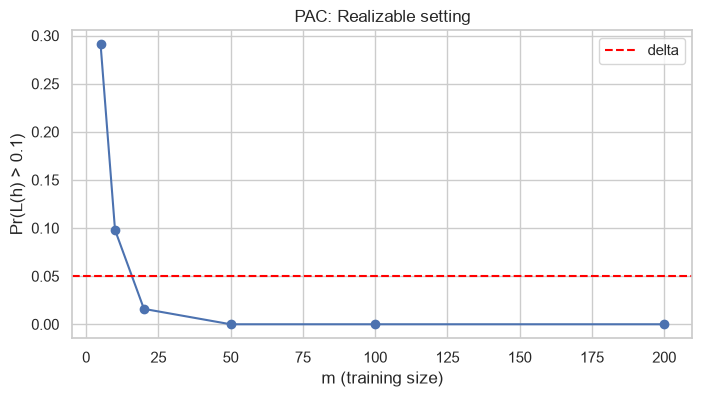

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(m, probs_pac, marker="o")
ax.set_xlabel("m (training size)")
ax.set_ylabel(f"Pr(L(h) > {epsilon})")
ax.set_title("PAC: Realizable setting")
ax.axhline(y=delta, color="red", linestyle="--", label="delta")
plt.legend()
plt.show()

For each m, we repeat the experiment 1000 times and we estimate Pr(L(h) > epsilon). This probability goes down quickly when m grows, and it goes below delta = 0.05 from m=20. This shows that the problem is PAC learnable in the realizable case. When m is large enough, ERM returns a good hypothesis (error below epsilon) with probability at least 1 - delta.

## V - From PAC to Agnostic PAC

In [11]:
datasets_noisy = []
for nbr_samples in m:
    samples = []
    for i in range(nbr_samples):
        x = random.uniform(0, 1)
        if x > teta:
            y = 1
        else:
            y = 0
        if random.random() < eta:
            y = 1 - y
        samples.append((x, y))

    datasets_noisy.append(samples)

In [12]:
for i in range(len(datasets_noisy)):
    best_teta, best_error = ERM(datasets_noisy[i])
    true_error = True_Error(teta, best_teta, 1000)
    print(f"m={m[i]}: empirical error = {best_error:.4f}, true error = {true_error:.4f}")

m=5: empirical error = 0.0000, true error = 0.0920
m=10: empirical error = 0.2000, true error = 0.4160
m=20: empirical error = 0.1500, true error = 0.2130
m=50: empirical error = 0.2400, true error = 0.0020
m=100: empirical error = 0.1600, true error = 0.0220
m=200: empirical error = 0.2200, true error = 0.0010


In [13]:
probs_agnostic = []

for nbr_samples in m:
    count = 0
    for repe in range(1000):
        samples = []
        for i in range(nbr_samples):
            x = random.uniform(0, 1)
            if x > teta:
                y = 1
            else:
                y = 0
            
            if random.random() < eta:
                y = 1 - y
            samples.append((x, y))

        best_teta, best_error = ERM(samples)
        true_error = True_Error(teta, best_teta, 1000)

        if true_error > epsilon:
            count += 1

    prob = count / 1000
    probs_agnostic.append(prob)
    print(f"m={nbr_samples}: Pr(L(h) > {epsilon}) = {prob:.4f}")

m=5: Pr(L(h) > 0.1) = 0.5160
m=10: Pr(L(h) > 0.1) = 0.4340
m=20: Pr(L(h) > 0.1) = 0.2940
m=50: Pr(L(h) > 0.1) = 0.0980
m=100: Pr(L(h) > 0.1) = 0.0270
m=200: Pr(L(h) > 0.1) = 0.0050


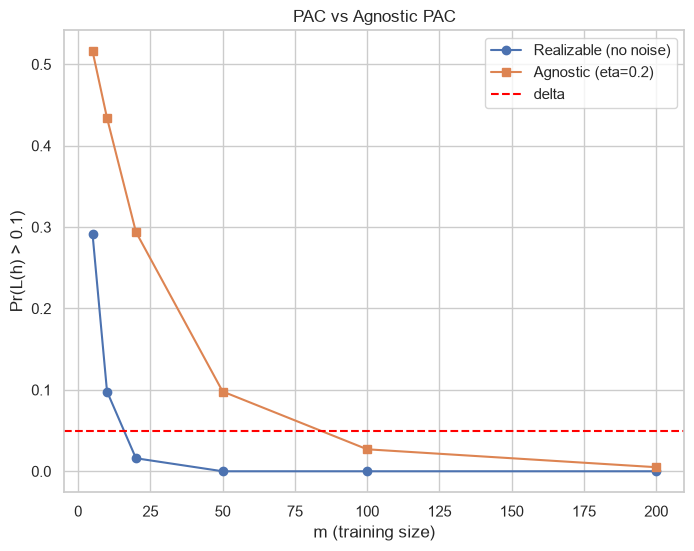

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(m, probs_pac, marker="o", label="Realizable (no noise)")
ax.plot(m, probs_agnostic, marker="s", label=f"Agnostic (eta={eta})")
ax.axhline(y=delta, color="red", linestyle="--", label="delta")
ax.set_xlabel("m (training size)")
ax.set_ylabel(f"Pr(L(h) > {epsilon})")
ax.set_title("PAC vs Agnostic PAC")
ax.legend()
plt.show()

With label noise (eta = 0.2), the empirical error is not 0 anymore so it doesn't necessarily exist an perfect hypothesis anymore. ERM cannot fit the flipped labels, so the error stays close to the noise level. The agnostic curve is above the realizable one and goes down more slowly. It reaches delta around m=100 instead of m=20. The generalization still improves when m grows.

## Conclusion
---
**Can the empirical error still reach zero?**

Not in general. With noise the training set has points that no threshold can classify correctly, so ERM cannot reach an empirical error of 0 (except by luck when m is very small). The lowest empirical error comes from the noise, which we cannot remove.

**Does increasing the number of training examples still improve the generalization performance?**

Yes, Pr(L(h) > epsilon) keeps going down when m grows, so more data still helps. We just need more points to reach the same confidence level as in the case without noise.

**How do your observations relate to the PAC and Agnostic PAC learning frameworks introduced during the lectures?**

The experiments without noise match the PAC framework (there is an perfect hypothesis). The empirical error can reach 0 and ERM converges fast. The experiments with noise match the Agnostic PAC framework (an perfect hypothesis doesn't exist). The empirical error cannot reach 0, but ERM still finds the best hypothesis of the class, and it needs more data to do it. Both cases are learnable, but noise increases the number of examples we need.